In [7]:
import os
from typing import TypedDict, Literal, Sequence
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langgraph.types import Send

CONTENT_TYPES = ["poem", "joke", "ci_poem"]

# 构建大模型
load_dotenv(override = True)

model = init_chat_model(
    model = "deepseek-flash",
    api_key = os.getenv("DEEPSEEK_API_KEY"),
    base_url = os.getenv("DEEPSEEK_BASE_URL"),
    extra_body = {"thinking": {"type": "disabled"}}
)

# 定义状态
# 全局状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem: str
    joke: str

# 私有状态
class WorkerState(TypedDict):
    content_type: Literal["poem", "joke", "ci_poem"]
    prompt: str

# 输入状态
class InputState(TypedDict):
    topic: str

# 输出状态
class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

# 定义结点
def worker_node(state: WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]
    content = model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }

# 定义动态分支的路由
def router(state: InputState) -> Sequence[Send]:
    router_prompt = "请生成关于 {} 的 {}"
    english2chinese = {
        "poem": "七言绝句",
        "joke": "笑话",
        "ci_poem": "中文词"
    }

    topic = state["topic"]
    return [
        Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": router_prompt.format(topic, english2chinese[content_type])
            }
        )
        for content_type in CONTENT_TYPES
    ]

# 构建图
builder = StateGraph(state_schema = OverAllState, input_schema = InputState, output_schema = OutputState)

builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map = ["worker_node"],
)

builder.add_edge("worker_node", END)

graph = builder.compile()

res = graph.invoke({"topic": "莲花"})
print(res)

{'poem': '《咏莲》\n玉立亭亭碧水滨，淤泥不染素衣身。\n中通外直清香远，君子风标自有神。\n\n注：我的诗作通过描绘莲花“出淤泥而不染”的形态，赞颂其高洁品格。首句以“玉立亭亭”展现莲的优雅姿态，次句“不染素衣身”暗喻其纯净本质。后两句化用周敦颐《爱莲说》意境，以“中通外直”状其形，“君子风标”点明其精神内核，整体借物喻人，传递对高尚情操的追求。', 'ci_poem': '## 莲花\n\n### 一、十六字令\n\n莲，碧水中央绽笑颜。清风过，香远溢人间。\n\n### 二、忆江南\n\n莲花好，六月满池娇。翠盖亭亭擎雨露，红妆点点映波涛。香韵入诗毫。\n\n### 三、如梦令\n\n池上清风微度，吹绽莲花无数。碧叶衬红妆，惹得蜻蜓频顾。休妒，休妒，自有暗香如故。\n\n### 四、调笑令\n\n莲叶，莲叶，翠盖田田层叠。清风拂过池边，碧水盈盈映天。天映，天映，一朵莲花初醒。\n\n### 五、长相思\n\n风一池，雨一池，池上莲花开几枝。红妆映碧漪。\n\n蝶来迟，蜻来迟，独立清波香暗驰。此心君可知。\n\n### 六、浣溪沙\n\n碧水池塘六月天，莲花初绽叶田田。清风一缕暗香传。\n\n不染淤泥身自洁，常随明月影同闲。人间君子独堪怜。\n\n### 七、卜算子\n\n生在水中央，不染尘和土。碧叶连天映日开，自有清香吐。\n\n风过舞蹁跹，雨打珠玑聚。纵使秋来落尽红，藕在泥深处。\n\n### 八、鹧鸪天\n\n六月池塘景最幽，莲花朵朵立波头。红衣映日娇欲语，翠盖临风颤未休。\n\n香淡淡，影悠悠，出泥不染自风流。世间多少丹青手，难画清姿一段秋。\n\n### 九、临江仙\n\n碧水悠悠浮翠盖，清风暗送幽香。莲花初绽满池塘。亭亭尘不染，默默韵尤长。\n\n明月一轮来相照，波光映影成双。此心高洁向何方。云间寻白鹭，梦里到潇湘。\n\n### 十、水调歌头\n\n碧水映晴日，翠盖满池塘。清风徐来时候，十里送幽香。不染淤泥浊气，自守冰心玉骨，独立水中央。蜂蝶莫相扰，高洁本无双。\n\n月色下，烟波上，影微茫。此身何寄，天地清处是吾乡。莫道秋来花落，且看泥中藕实，丝缕韵悠长。千古爱莲说，君子共流芳。\n\n---\n\n*注：以上词作分别依《十六字令》《忆江南》《如梦令》《调笑令》《长相思》《浣溪沙》《卜算子》《鹧鸪天》《临江仙》《水调歌头》词牌格律而作，

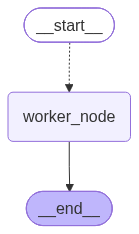

In [8]:
from IPython.display import display
display(graph)